In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import platform
from IPython.display import display, Markdown

import vizarr
import zarr

import cdk
from cdk.analysis import cell as m

In [2]:
zarr_url = "https://tyrosine.int.bnext.bio:8443/20261002-cephla-test/lysateGUVsinsolution_2026-10-02_11-55-52.257519.zarr"
parquet_url = "https://data.nucleus.engineering/microscopy/valine/820-720-620-520-420_2026-08-26_12-32-14.888144.parquet"
platemap_file = None

In [3]:
# Parameters
zarr_file = "/storage/storage/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.zarr"
zarr_url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.zarr"
parquet_file = "/storage/storage/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.parquet"
parquet_url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.parquet"
platemap_file = "/storage/storage/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.platemap.csv"
platemap_url = "https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.platemap.csv"


In [4]:
data = m.load(parquet_url, platemap_file)

In [5]:
exp = zarr_url.split("/")[-1]

meta = f"""
# {exp}

**Runtime**
- Analysis host: {platform.node()}
- Python version: {platform.python_version()}
- CDK version: {cdk.__version__}

**Data**
- Zarr: {zarr_url}
- Analysis Parquet: {parquet_url}
- Platemap: {platemap_url}
"""

display(Markdown(meta))


# 20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.zarr

**Runtime**
- Analysis host: tyrosine.int.bnext.bio
- Python version: 3.12.11
- CDK version: 0.6.4

**Data**
- Zarr: https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.zarr
- Analysis Parquet: https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.parquet
- Platemap: https://data.nucleus.engineering/microscopy/nucleus-bnext-01/20261013-devstudio-liposomes-timeseries_2026-10-13_12-07-24.011026.platemap.csv


In [6]:
viewer = vizarr.Viewer(height="800px")
viewer.add_image(source=zarr_url, name="test")
viewer

## Check Cell Segmentation
Optionally check cells - - will take a few seconds since this reads from a zarr file! If you want faster, load the zarr specifically into this folder. Dont use a URL.

,Label,Area (um^2),Diameter (Equivalent) (um),Diameter (Feret) (um),Length Major (um),Length Minor (um),Perimeter (um),Intensity Mean (GFP),Intensity Mean (Rhodamine),Intensity Max (GFP),...,Well,Pyramid Level,Date,Experiment,Type,Name,Person,Cytosol Type,DNA,Membrane
2315164,7797,61.639936,8.859030,9.776000,8.993506,8.729712,27.361352,4077.559633,2510.458716,6102.0,...,E9,2,2026-10-13,Devstudio Liposome Workshop,Sample,MC 2,Michael Clear,Nucleus,pT7-deGFP,3:1 POPC:Chol
756857,15055,199.057408,15.920043,19.172313,17.208535,15.007479,54.099726,21544.215909,29236.232955,22719.0,...,D8,2,2026-10-13,Devstudio Liposome Workshop,Sample,BP,Becky Pferdehirt,Nucleus,pT7-deGFP,3:1 POPC:Chol
1917078,6346,134.024448,13.063125,14.831758,13.697623,12.589701,43.206795,8356.535865,8493.421941,10133.0,...,E6,2,2026-10-13,Devstudio Liposome Workshop,Sample,MB 1,Mike Booth (1),Nucleus,pT7-deGFP,3:1 POPC:Chol
1797726,5299,100.094208,11.289106,12.784000,11.725521,10.963861,36.385352,3805.847458,7537.519774,4804.0,...,E6,2,2026-10-13,Devstudio Liposome Workshop,Sample,MB 1,Mike Booth (1),Nucleus,pT7-deGFP,3:1 POPC:Chol


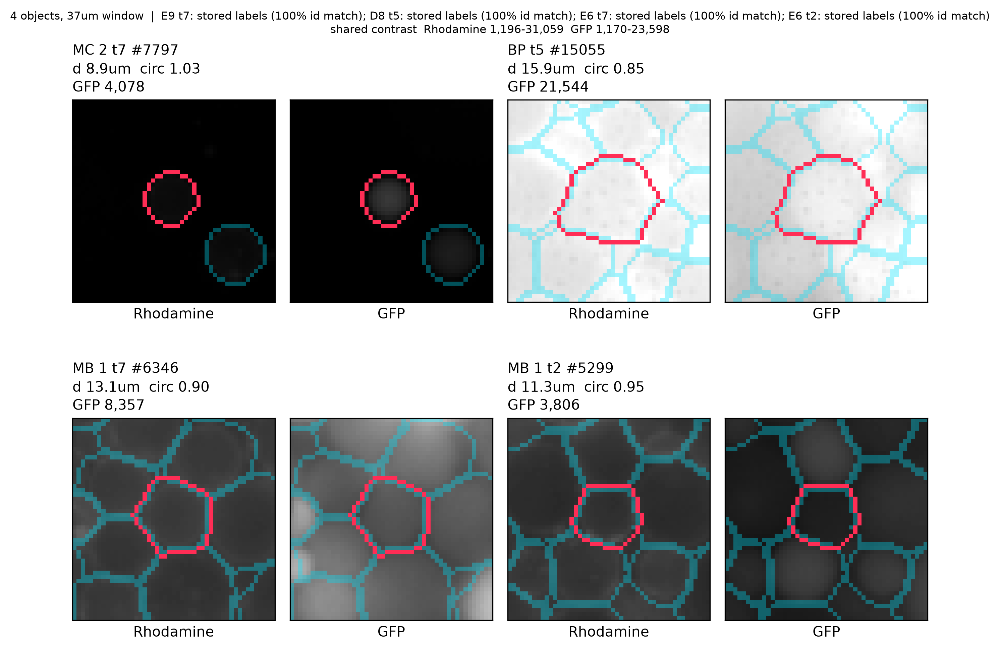

In [7]:
NUM_CELLS_TO_CHECK = 4
m.plot_cell_grid(data, zarr_url, n=NUM_CELLS_TO_CHECK, pyramid_level=2)
# example_indexed_data = data[(data.Well == data.Well.unique()[0]) & (data.Timepoint == 0)]
# m.plot_cell_grid(example_indexed_data, ZARR_URL, n=5, channels=["Alexa Fluor 647"], pyramid_level=2) #show just one channel channels
# m.plot_cell_grid(one, ZARR_URL, n=NUM_CELLS_TO_CHECK, contrast="tile", pyramid_level=2) #make the intensity contrast scaled by tile not by the whole grid




## Summary Plots

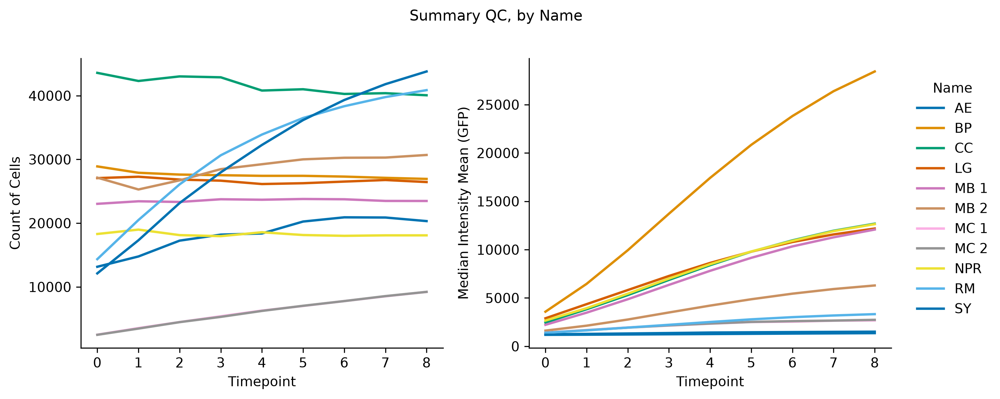

In [8]:
_ = m.plot_summary(data) # facet="other_col"
# m.plot_summary(data, hue="Name", channels=["GFP", "Alexa Fluor 647"]) #one panel per channel, in this order
# m.plot_summary(data, hue="Name", normalize=True) # every intensity panel as fold change off its first timepoint




In [9]:
_ = m.plot_size(data)

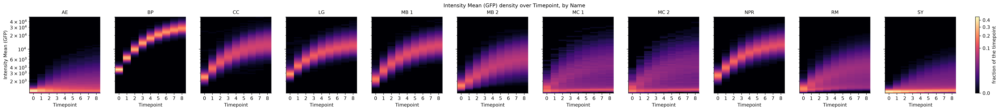

In [10]:
_ = m.plot_density_over_time(data)  # logy=False for a bounded measure

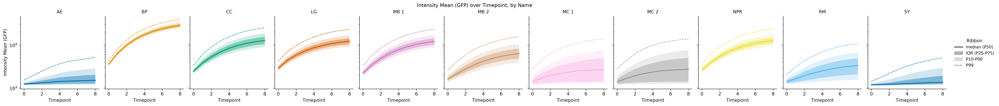

In [11]:
_ = m.plot_quantile_ribbon(data) #facet="other_col"

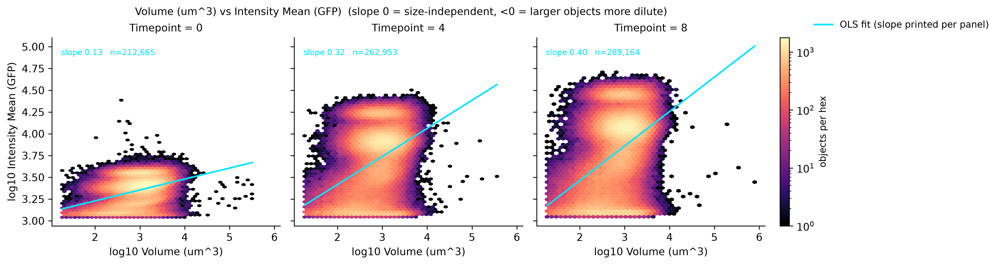

In [12]:
_ = m.plot_size_expression(data) #, timepoints=[1,3,5,7,9], facet="other_col")

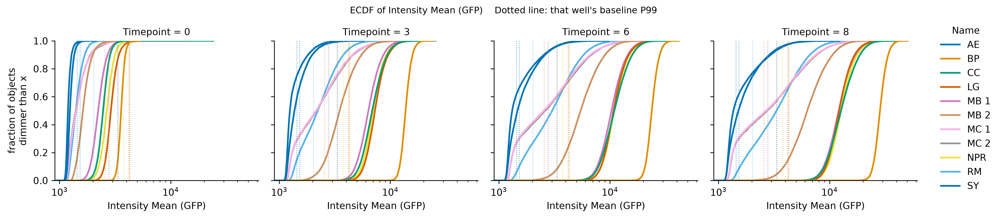

In [13]:
# tells you what populations there are, and how long tails are
_ = m.plot_ecdf(data)

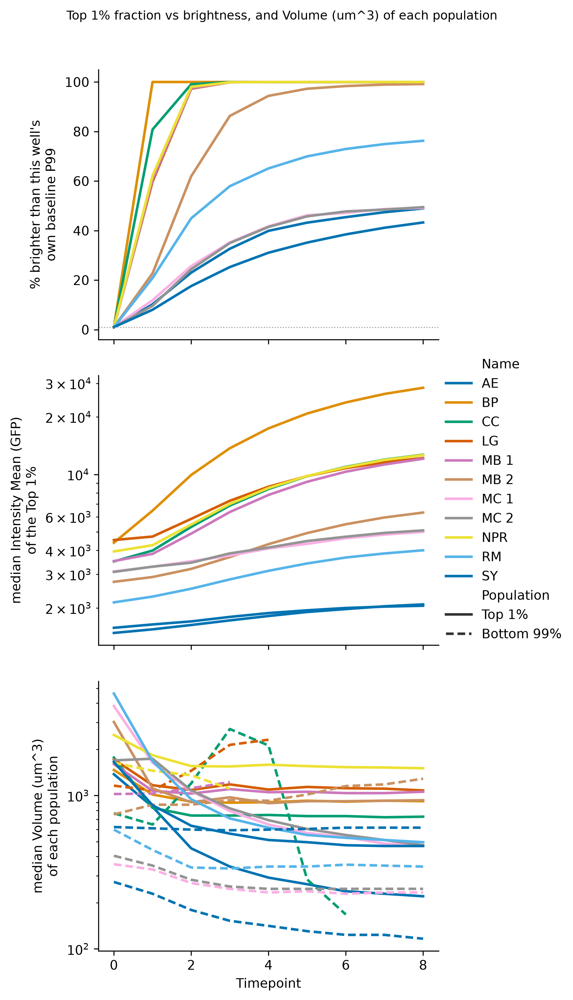

In [14]:
# how many cells turn on, and how bright did they get.Default shows the 99th percentaile
_ = m.plot_positive_fraction(data, gate_quantile=0.99) #,facet="other_col"

In [15]:
_ = m.plot_fogplot(data)

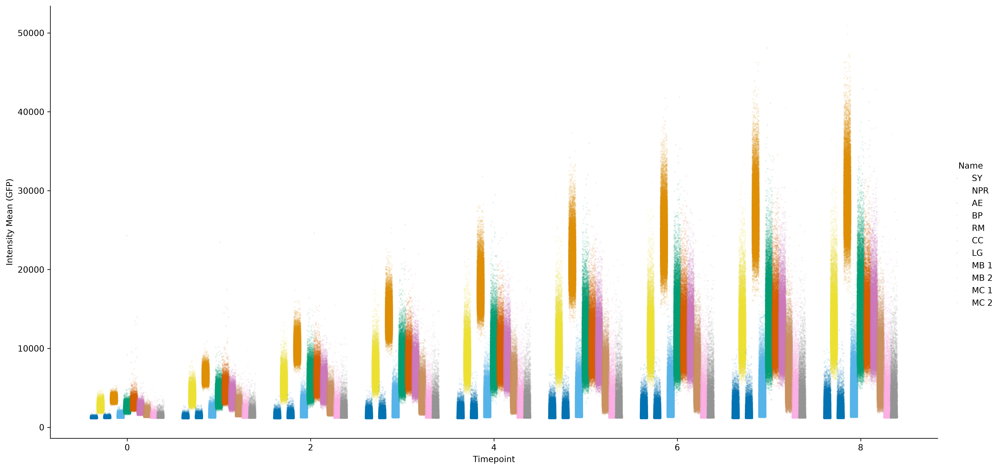

In [16]:
_ = m.plot_fogplot_compare(data)